# 04 · Why does the model say what it says?

A model nobody can explain is hard to trust. Here we use **SHAP** to break each prediction into
"pushes" from each feature, then look at the songs the model got most wrong.

In [1]:
import sqlite3
import sys
from pathlib import Path

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from lightgbm import LGBMRegressor

from src.data import FEATURES, get_xy, load_clean, split_tracks

DB_PATH = Path("..") / "data" / "spotify.db"
df = load_clean(DB_PATH)
train, val, test = split_tracks(df)
X_train, y_train = get_xy(train)
X_val, y_val = get_xy(val)

# Same model and settings as notebook 03. (Step 7 will save it to a file so we stop retraining.)
model = LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63, random_state=42, verbose=-1)
model.fit(X_train, y_train)

BLUE, RED, INK, INK_2, GRID, SURFACE = "#2a78d6", "#e34948", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "xtick.color": INK_2, "ytick.color": INK_2, "axes.labelcolor": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})

## 1. How SHAP works

Every prediction starts from the same **starting point**: the average popularity of the train songs.
Then each feature **pushes** the guess up or down. The pushes always add up exactly to the final prediction:

> prediction = starting point + push from genre + push from energy + ... + push from mode

That's what makes SHAP useful: nothing is hidden. We work it out for 2,000 validation songs (all 11,485 would just be slower).

In [2]:
explainer = shap.TreeExplainer(model)
sample = X_val.sample(2000, random_state=0)
explanation = explainer(sample)

starting_point = explanation.base_values[0]
print(f"starting point: {starting_point:.2f}   (average popularity of the train songs: {y_train.mean():.2f})")

# Check the promise: starting point + all pushes = the model's prediction, for every song.
rebuilt = explanation.values.sum(axis=1) + explanation.base_values
print("pushes add up to the prediction for all 2,000 songs:", np.allclose(rebuilt, model.predict(sample), atol=1e-3))

starting point: 37.45   (average popularity of the train songs: 37.45)
pushes add up to the prediction for all 2,000 songs: True


## 2. Explaining one song

This is exactly what the app will show a visitor: the starting point, the biggest pushes, and the result.

In [3]:
def explain(row_position, top=6):
    """Starting point, the `top` biggest pushes, and the rest lumped together."""
    pushes = pd.Series(explanation.values[row_position], index=FEATURES)
    song = sample.iloc[row_position]
    labels = {f: f"{f} = {song[f]}" if f == "track_genre" else f"{f} = {song[f]:.3g}" for f in FEATURES}
    biggest = pushes.reindex(pushes.abs().sort_values(ascending=False).index)[:top]
    rest = pushes.drop(biggest.index).sum()
    parts = pd.concat([biggest.rename(index=labels), pd.Series({f"{len(FEATURES) - top} other features": rest})])
    return parts, starting_point + pushes.sum()

# Pick a well-predicted, fairly popular song so the example is meaningful.
predicted = model.predict(sample)
actual = y_val.loc[sample.index].to_numpy()
good = np.where((np.abs(predicted - actual) < 3) & (actual > 60))[0][0]
info = val.loc[sample.index[good]]
parts, final = explain(good)
print(f"{info.track_name} by {info.artists} ({info.track_genre}): actual {info.popularity}, predicted {final:.1f}")
parts.round(2)

With You by Linkin Park (metal): actual 64, predicted 61.8


track_genre = metal      21.78
loudness = -4             2.31
energy = 0.978           -1.37
tempo = 197              -1.19
acousticness = 0.0037     0.77
valence = 0.359           0.76
9 other features          1.28
dtype: float64

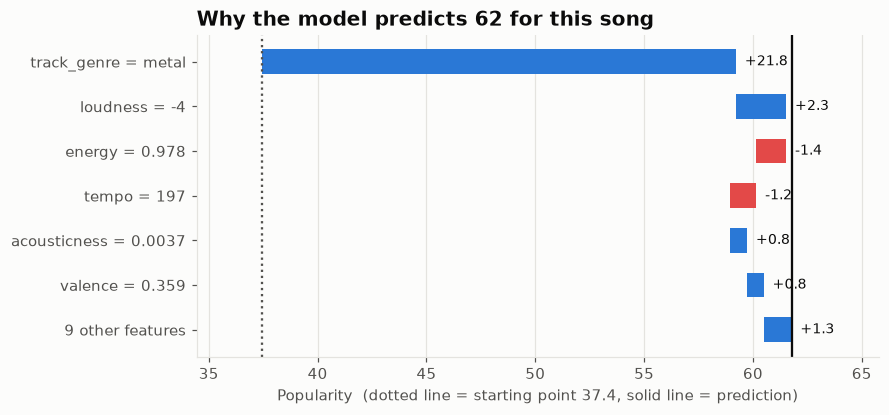

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
# Each bar starts where the previous one ended, so they chain from the starting point to the prediction.
running = starting_point
order = list(parts.items())
for i, (label, push) in enumerate(order):
    y = len(order) - 1 - i
    ax.barh(y, push, left=running, color=BLUE if push >= 0 else RED, height=0.55)
    ax.text(max(running, running + push) + 0.4, y, f"{push:+.1f}", va="center", color=INK, fontsize=9)
    running += push
ax.set_yticks(range(len(order)), [label for label, _ in order][::-1])
ends = np.cumsum([starting_point] + list(parts.values))
ax.set_xlim(min(ends) - 3, max(ends) + 4)
ax.axvline(starting_point, color=INK_2, linewidth=1.5, linestyle=":")
ax.axvline(final, color=INK, linewidth=1.5)
ax.set_title(f"Why the model predicts {final:.0f} for this song")
ax.set_xlabel(f"Popularity  (dotted line = starting point {starting_point:.1f}, solid line = prediction)")
ax.grid(axis="y", visible=False)
plt.show()

**How to read it:** start at the dotted line (the average). Each bar moves the guess: blue bars push it up,
red bars pull it down. Where the last bar ends is the prediction (solid line).

## 3. Which features matter most overall?

Average the **size** of each feature's push over all 2,000 songs (ignoring whether it pushes up or down).

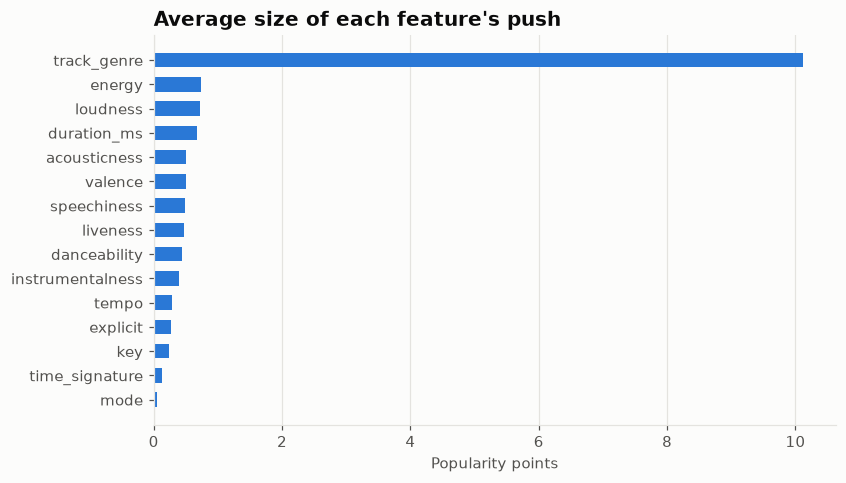

track_genre         10.12
energy               0.74
loudness             0.73
duration_ms          0.68
acousticness         0.50
valence              0.50
speechiness          0.48
liveness             0.47
danceability         0.44
instrumentalness     0.39
tempo                0.29
explicit             0.27
key                  0.24
time_signature       0.13
mode                 0.06
dtype: float64

In [5]:
importance = pd.Series(np.abs(explanation.values).mean(axis=0), index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.set_title("Average size of each feature's push")
ax.set_xlabel("Popularity points")
ax.grid(axis="y", visible=False)
plt.show()

importance.sort_values(ascending=False).round(2)

**Genre pushes about 10 points** on an average song. The next biggest, energy and loudness, push under 1 point each.
This matches notebook 02: genre carries most of what the data can tell us.

## 4. The energy hump, seen through SHAP

Each dot is one song: its energy (left to right) and how much energy pushed its prediction (up or down).

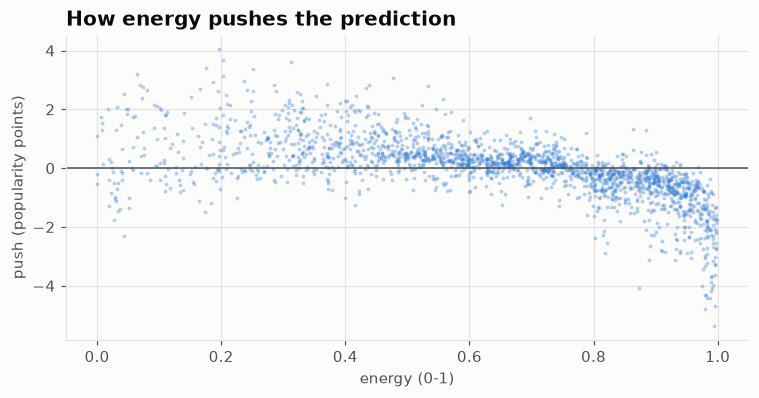

In [6]:
energy_col = FEATURES.index("energy")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(sample["energy"], explanation.values[:, energy_col], s=6, alpha=0.35, color=BLUE, linewidths=0)
ax.axhline(0, color=INK_2, linewidth=1)
ax.set_title("How energy pushes the prediction")
ax.set_xlabel("energy (0-1)")
ax.set_ylabel("push (popularity points)")
plt.show()

**This is not the hump from notebook 02.** Here, low and middle energy get a small push up, and only the most
intense songs (above about 0.8) get pushed down, by up to 5 points. The left side of the hump has gone.

Why? Notebook 02 looked at energy **on its own**. Quiet songs come mostly from genres that are less popular
(think ambient, classical, sleep music), so they looked unpopular *because of their genre*. SHAP measures energy's
push **after** genre has had its say, and once genre is accounted for, being quiet isn't a problem at all.

This trap is called **confounding**: a hidden third thing (genre) makes two things (energy and popularity) look
linked. It's a good reason not to trust single-feature charts alone. The drop for very intense songs is still a
curve a straight-line model can't draw.

## 5. The songs the model got most wrong

In [7]:
v = val.assign(predicted=model.predict(X_val).round(1))
v["error"] = (v["predicted"] - v["popularity"]).round(1)
worst = v.reindex(v["error"].abs().sort_values(ascending=False).index).head(20)
worst[["track_name", "artists", "track_genre", "popularity", "predicted", "error"]]

,track_name,artists,track_genre,popularity,predicted,error
27641,Howl,Florence + The Machine,alternative,1,72.2,71.2
34791,Left and Right,Charlie Puth;Jung Kook,dance,2,70.6,68.6
72245,ily (i love you baby),Surf Mesa;Emilee,house,1,68.8,67.8
54351,Sensual Bebé,Jhayco,latino,1,68.5,67.5
45374,One Time,Justin Bieber,pop,3,70.1,67.1
40139,Mistletoe,Justin Bieber,pop,4,70.8,66.8
70940,You Belong With Me (Taylor’s Version),Taylor Swift,pop,9,75.4,66.4
34362,Land of Confusion,Disturbed,metal,1,64.6,63.6
11857,Close Your Eyes,Kim Petras,dance,3,66.1,63.1
70670,Yellow,Coldplay,pop,4,66.5,62.5


19 of the 20 worst are songs the model rated **high** that are listed with popularity 1 to 9, and many are
famous: Coldplay's *Yellow*, Justin Bieber, Taylor Swift. Let's look these up in the raw data.

In [8]:
with sqlite3.connect(DB_PATH) as conn:
    lookup = pd.read_sql("""
        SELECT track_name, artists, album_name, popularity
        FROM tracks_raw
        WHERE (track_name = 'Yellow' AND artists = 'Coldplay')
           OR (track_name = 'Howl' AND artists = 'Florence + The Machine')
    """, conn)
lookup

,track_name,artists,album_name,popularity
0,Howl,Florence + The Machine,Helloween Party,1
1,Howl,Florence + The Machine,Pop & Halloween,1
2,Howl,Florence + The Machine,Happy Haunted Halloween Tunes,1
3,Howl,Florence + The Machine,Halloween Scary Party,0
4,Yellow,Coldplay,Hits Hits Hits,3
5,Yellow,Coldplay,Alternative Rock Mixtape,4


**Found it.** The dataset only has these songs on **compilation albums** ("Hits Hits Hits", "Helloween Party"),
never the original release. Spotify gives popularity per release, so the compilation copy scores 1 to 4 while the
real *Yellow* is hugely popular. Our cleaning kept the most popular release **that was in the dataset**, but
here the good one was never collected.

So the model is arguably **right** and the label is misleading: a pop song with these sounds usually is popular.
This is called **label noise**. It also means our error scores are a bit worse than the model really deserves.

## 6. Where the model struggles: big hits

In [9]:
bands = pd.cut(v["popularity"], [0, 20, 40, 60, 80, 100], labels=["1-20", "21-40", "41-60", "61-80", "81-100"])
by_band = v.assign(abs_error=v["error"].abs()).groupby(bands, observed=True)["abs_error"].agg(["mean", "count"]).round(1)
print(f"highest prediction the model ever makes: {v['predicted'].max():.0f}")
by_band

highest prediction the model ever makes: 84


,mean,count
popularity,,
1-20,9.5,2134
21-40,6.7,4336
41-60,7.7,3778
61-80,15.1,1171
81-100,27.0,66


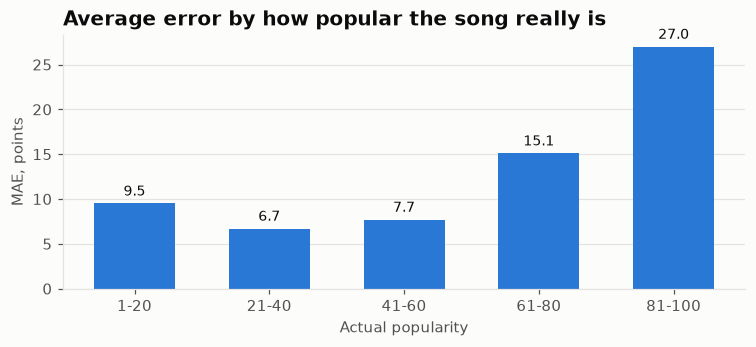

In [10]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(by_band.index.astype(str), by_band["mean"], color=BLUE, width=0.6)
ax.bar_label(ax.containers[0], labels=[f"{m:.1f}" for m in by_band["mean"]], padding=3, color=INK, fontsize=9)
ax.set_title("Average error by how popular the song really is")
ax.set_xlabel("Actual popularity")
ax.set_ylabel("MAE, points")
ax.grid(axis="x", visible=False)
plt.show()

The model is off by about 7 points for ordinary songs but **27 points for real hits (81-100)**, and it never
predicts above the mid-80s. Hits depend on things not in this data (a famous artist, a viral moment), so the
model plays it safe and pulls every guess toward the middle. This is common in regression and is called
**regression toward the mean**.

What this means for the app: it's good at "is this a typical pop song or a niche jazz track?",
and not good at spotting the next number-one hit. The README should say so.

## Your turn

In one or two sentences: if a recruiter asked *"why is your model's error so large for some famous songs?"*,
what would you answer? Write it here (double-click to edit).

...